# Evaluation-held-out public friendship networks
This is a new **post-collection structural-transfer benchmark**, not a change to the locked 24 primary tests. It uses only the 896 original attempts (890 valid); all six supplemental graphs stay excluded.
The new public networks were excluded from baseline fitting, not necessarily from LLM pretraining. The fixed generated rosters cannot predict named people or validate national/cultural behavior. Two source studies and overlapping subgraphs do not supply hundreds of independent human samples.

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'analysis_heldout/protocol.json').is_file())
sys.path.insert(0, str(ROOT))
OUT = ROOT/'outputs/heldout_evaluation/20261105_v1'
seal = json.loads((OUT/'evaluation_manifest.json').read_text())
assert seal['status'] == 'COMPLETE_HELDOUT_STRUCTURAL_EVALUATION_WITH_CAVEATS'
assert seal['supplemental_graphs'] == seal['paid_calls'] == seal['ledger_queries'] == 0
for name, record in seal['artifacts'].items():
    path = OUT/name
    assert path.stat().st_size == record['bytes'] and hashlib.sha256(path.read_bytes()).hexdigest() == record['sha256'], name
for name, expected in seal['code_sha256'].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest() == expected, name
assert hashlib.sha256((ROOT/'outputs/primary_analysis/20261105/evaluation_manifest.json').read_bytes()).hexdigest() == seal['previous_primary_seal_sha256']
from analysis_primary.core import load_inputs
_, primary, _ = load_inputs(ROOT)
candidate = pd.read_csv(OUT/'candidate_metrics.csv')
original = candidate[candidate.kind.eq('LLM')]
assert len(original) == 896 and original.valid.sum() == 890
assert set(original.run_id) == set(primary.original_run_id)
print('Primary-only cohort and all benchmark artifact/code hashes verified.')


Primary-only cohort and all benchmark artifact/code hashes verified.


## Public data and sampling
SNAP supplies ten Facebook alter graphs: keep roster nodes from .feat files, ignore all feature values, and exclude the ego. Reciprocal edge-list rows become one simple edge. Some alter rosters include isolates.
The SocioPatterns survey becomes one observed-roster graph of positive-reporting nominators, restricted to nominations between those roster members, then OR-projected. This cannot recover zero-nominating/nonresponding people; missing survey reports are not fabricated as zero-tie observations. No sensor/contact graph is substituted for friendship.
Take 32 deterministic uniform induced 50-node draws per cohort, retaining isolates, empty and disconnected outcomes. These draws overlap. The ten Facebook records also overlap with each other. Cohort/source summaries are descriptive, without independent-sample CIs. See source attribution/license notes in docs/HELDOUT_REAL_WORLD_EVALUATION.md.

In [2]:
quality = pd.read_csv(OUT/'dataset_quality.csv')
overlap = pd.read_csv(OUT/'cohort_overlap.csv')
display(quality[['source','cohort','observed_roster_nodes','observed_edges','observed_isolates','dropped_external_nominations']])
print('Facebook cohort pairs sharing observed nodes:', int(overlap.shared_nodes.gt(0).sum()), '/', len(overlap))
display(json.loads((OUT/'development_fit.json').read_text()))


,source,cohort,observed_roster_nodes,observed_edges,observed_isolates,dropped_external_nominations
0,snap_facebook,FB01,347,2519,14,0
1,snap_facebook,FB02,1045,26749,11,0
2,snap_facebook,FB03,227,3192,3,0
3,snap_facebook,FB04,159,1693,9,0
4,snap_facebook,FB05,170,1656,2,0
5,snap_facebook,FB06,66,270,5,0
6,snap_facebook,FB07,792,14024,6,0
7,snap_facebook,FB08,755,30025,8,0
8,snap_facebook,FB09,547,4813,13,0
9,snap_facebook,FB10,59,146,7,0


Facebook cohort pairs sharing observed nodes: 22 / 45


{'BA_m': 5,
 'ER_p': 0.18893569470401766,
 'WS_grid': [{'mean_clustering': 0.666666666666667,
   'p': 0.0,
   'squared_error': 0.04664737669117011},
  {'mean_clustering': 0.5892531080031083,
   'p': 0.05,
   'squared_error': 0.01920066911658347},
  {'mean_clustering': 0.5220277951215451,
   'p': 0.1,
   'squared_error': 0.005089561990411203},
  {'mean_clustering': 0.40160487949550444,
   'p': 0.2,
   'squared_error': 0.0024090181297235754},
  {'mean_clustering': 0.26219218766323543,
   'p': 0.4,
   'squared_error': 0.035530154396814874},
  {'mean_clustering': 0.20467304321280716,
   'p': 0.6,
   'squared_error': 0.06052268436832222},
  {'mean_clustering': 0.19136816308691307,
   'p': 0.8,
   'squared_error': 0.06724606673869292},
  {'mean_clustering': 0.1888649637417536,
   'p': 1.0,
   'squared_error': 0.06855058437353768}],
 'WS_k': 10,
 'WS_p': 0.2,
 'clustering_target': 0.45068662895213624,
 'density_target': 0.18893569470401766,
 'development_communities': 7,
 'development_records

## Baselines and distance meaning
Fit ER density, BA attachment count, and WS neighborhood/rewiring only on the old eight-network panel; average the two Tailor waves first so seven communities have equal weight. Each baseline has eight independent Monte Carlo banks of 56 synthetic 50-node graphs. All new source graphs are excluded from fitting.
Wasserstein-1 compares distributions of each bounded graph-level metric separately. Within every frozen method/model group, weight the seven instruction conditions equally, dividing each condition's 1/7 among its valid outcomes. Failures stay recorded but are not zero-filled; distances are conditional on success. Baseline banks and target node draws have uniform weights.
Average cohort distances equally within each source. The bank min/max range is Monte Carlo sensitivity, **not a confidence interval**. Do not optimize or interpret a composite winner. G(n,m) and degree-preserving controls use target information and never enter the transfer ranking.

In [3]:
targets = pd.read_csv(OUT/'heldout_sample_metrics.csv')
distances = pd.read_csv(OUT/'per_cohort_distances.csv')
def ecdf_w1(left, right, weights):
    order = np.argsort(left)
    x = np.asarray(left)[order]
    cumulative = np.r_[0., np.cumsum(np.asarray(weights)[order]) / np.sum(weights)]
    y = np.sort(np.asarray(right))
    grid = np.unique(np.r_[x, y])
    fx = cumulative[np.searchsorted(x, grid[:-1], side='right')]
    fy = np.searchsorted(y, grid[:-1], side='right') / len(y)
    return float(np.sum(np.diff(grid) * np.abs(fx-fy)))
maximum_error = 0.
for row in distances.itertuples():
    group = candidate[candidate.candidate.eq(row.candidate) & candidate.bank.eq(row.bank)]
    valid = group[group.valid & group[row.metric].notna()]
    if row.kind == 'LLM':
        counts = valid.condition.value_counts()
        assert len(counts) == 7
        weights = valid.condition.map(lambda c: 1./(7*counts[c])).to_numpy()
    else:
        weights = np.ones(len(valid))/len(valid)
    human = targets[targets.source.eq(row.source) & targets.cohort.eq(row.cohort)]
    maximum_error = max(maximum_error, abs(ecdf_w1(valid[row.metric].to_numpy(), human[row.metric].to_numpy(), weights)-row.w1))
assert maximum_error < 1e-12
print('Independent ECDF integration checked', len(distances), 'distances; max error =', maximum_error)
summary = pd.read_csv(OUT/'source_distance_summary.csv')
display(summary)


Independent ECDF integration checked 2640 distances; max error = 1.1102230246251565e-15


,source,candidate,kind,metric,mean_w1,min_bank_w1,max_bank_w1,banks
0,snap_facebook,Baseline:BA,baseline,avg_clustering_coef,0.145449,0.144410,0.146381,8
1,snap_facebook,Baseline:BA,baseline,degree_gini,0.211804,0.210022,0.213534,8
2,snap_facebook,Baseline:BA,baseline,density,0.097230,0.097230,0.097230,8
3,snap_facebook,Baseline:BA,baseline,global_efficiency,0.363322,0.362871,0.363691,8
4,snap_facebook,Baseline:BA,baseline,prop_nodes_lcc,0.422438,0.422438,0.422438,8
...,...,...,...,...,...,...,...,...
223,sociopatterns_friendship,LLM:sequential:gpt-6-sol,LLM,degree_gini,0.129073,0.129073,0.129073,1
224,sociopatterns_friendship,LLM:sequential:gpt-6-sol,LLM,density,0.115835,0.115835,0.115835,1
225,sociopatterns_friendship,LLM:sequential:gpt-6-sol,LLM,global_efficiency,0.402825,0.402825,0.402825,1
226,sociopatterns_friendship,LLM:sequential:gpt-6-sol,LLM,prop_nodes_lcc,0.580000,0.580000,0.580000,1


## Conditional controls: not transfer baselines
Each held-out sample has eight G(n,m) controls and eight finite degree-swap controls. Degree swaps preserve the exact roster, degree sequence and edge count; 10m swaps do not establish uniform mixing. A target/control residual is defined only if all eight succeed, and a cohort summary only if all 32 targets are complete. No failed control is silently zero-filled or given extra weight.
These checks ask how much observed clustering/closure remains after conditioning on density or degrees. They do not validate LLM realism and are not null p-values.

In [4]:
controls = pd.read_csv(OUT/'conditional_control_metrics.csv')
joined = controls.merge(targets[['source','cohort','draw','density','degree_gini']], on=['source','cohort','draw'], suffixes=('', '_target'), validate='many_to_one')
assert np.allclose(joined.loc[joined.success,'density'], joined.loc[joined.success,'density_target'], atol=1e-12, rtol=0)
degree = joined.control.eq('degree_swap') & joined.success
assert np.allclose(joined.loc[degree,'degree_gini'], joined.loc[degree,'degree_gini_target'], atol=1e-12, rtol=0)
print('Conditional draws:', len(controls), '| failed:', int((~controls.success).sum()))
display(pd.read_csv(OUT/'conditional_residuals.csv'))


Conditional draws: 5632 | failed: 0


,source,cohort,control,metric,target_draws,complete_target_draws,failed_control_draws,mean_target_minus_control,status
0,snap_facebook,FB01,Gnm,density,32,32,0,0.000000,complete_descriptive
1,snap_facebook,FB01,Gnm,avg_clustering_coef,32,32,0,0.218685,complete_descriptive
2,snap_facebook,FB01,Gnm,global_efficiency,32,32,0,-0.093708,complete_descriptive
3,snap_facebook,FB01,Gnm,transitivity,32,32,0,0.374928,complete_descriptive
4,snap_facebook,FB01,Gnm,degree_gini,32,32,0,0.218079,complete_descriptive
...,...,...,...,...,...,...,...,...,...
127,sociopatterns_friendship,School2013,degree_swap,avg_clustering_coef,32,32,0,0.277102,complete_descriptive
128,sociopatterns_friendship,School2013,degree_swap,global_efficiency,32,32,0,-0.120298,complete_descriptive
129,sociopatterns_friendship,School2013,degree_swap,transitivity,32,32,0,0.404428,complete_descriptive
130,sociopatterns_friendship,School2013,degree_swap,degree_gini,32,32,0,0.000000,complete_descriptive


### 01 heldout transfer
Metric-specific transfer distances; smaller is closer on that metric, not generally better. Baseline entries average eight banks.

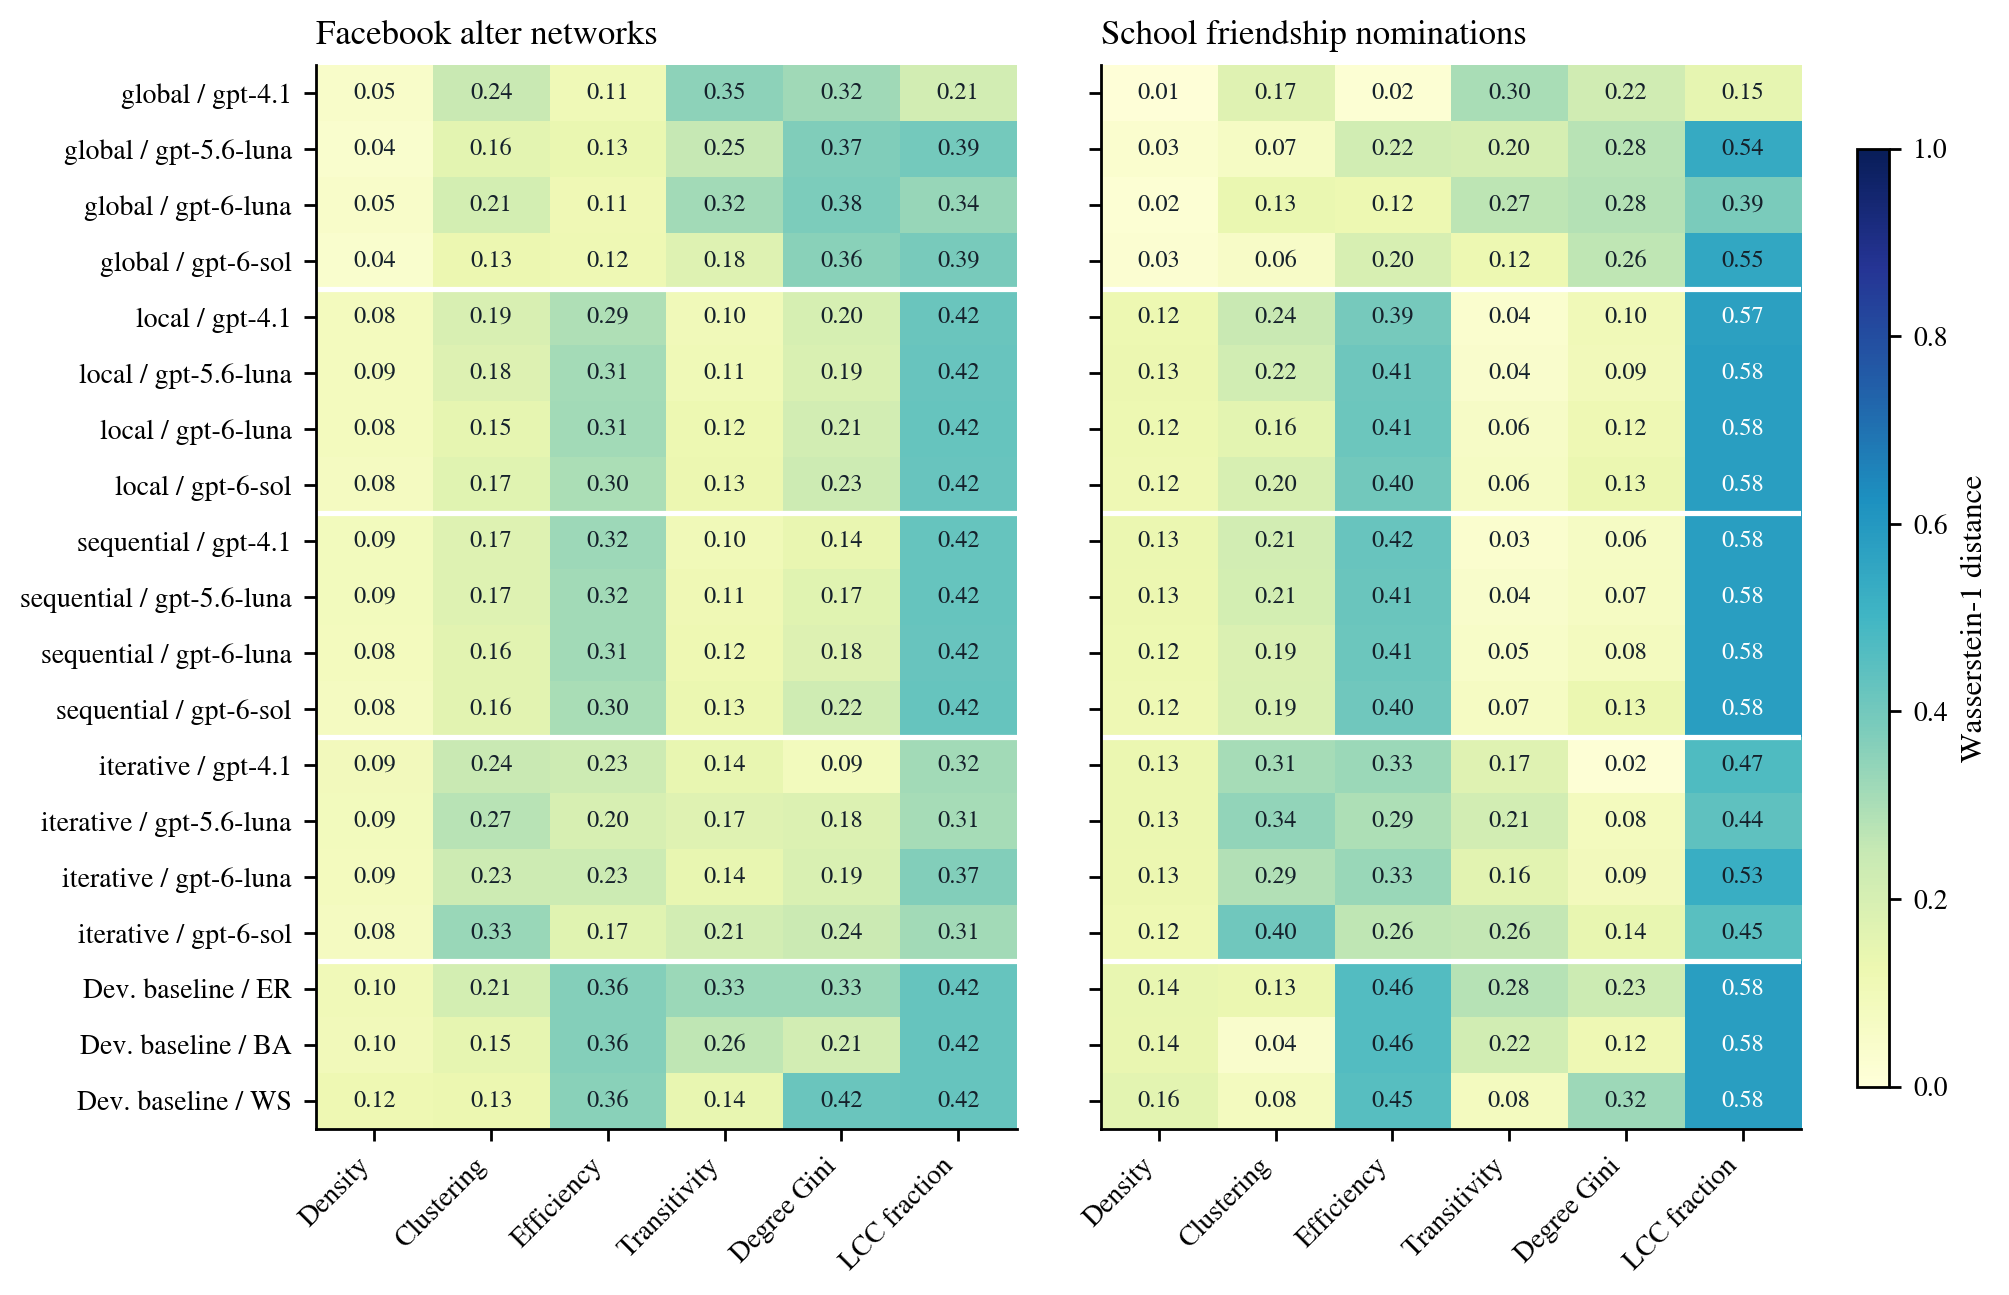

### 02 sampling shift
Open circles: complete observed roster. Diamonds: means of 32 induced 50-node draws. Lines: minimum-to-maximum node-draw range, NOT confidence intervals.

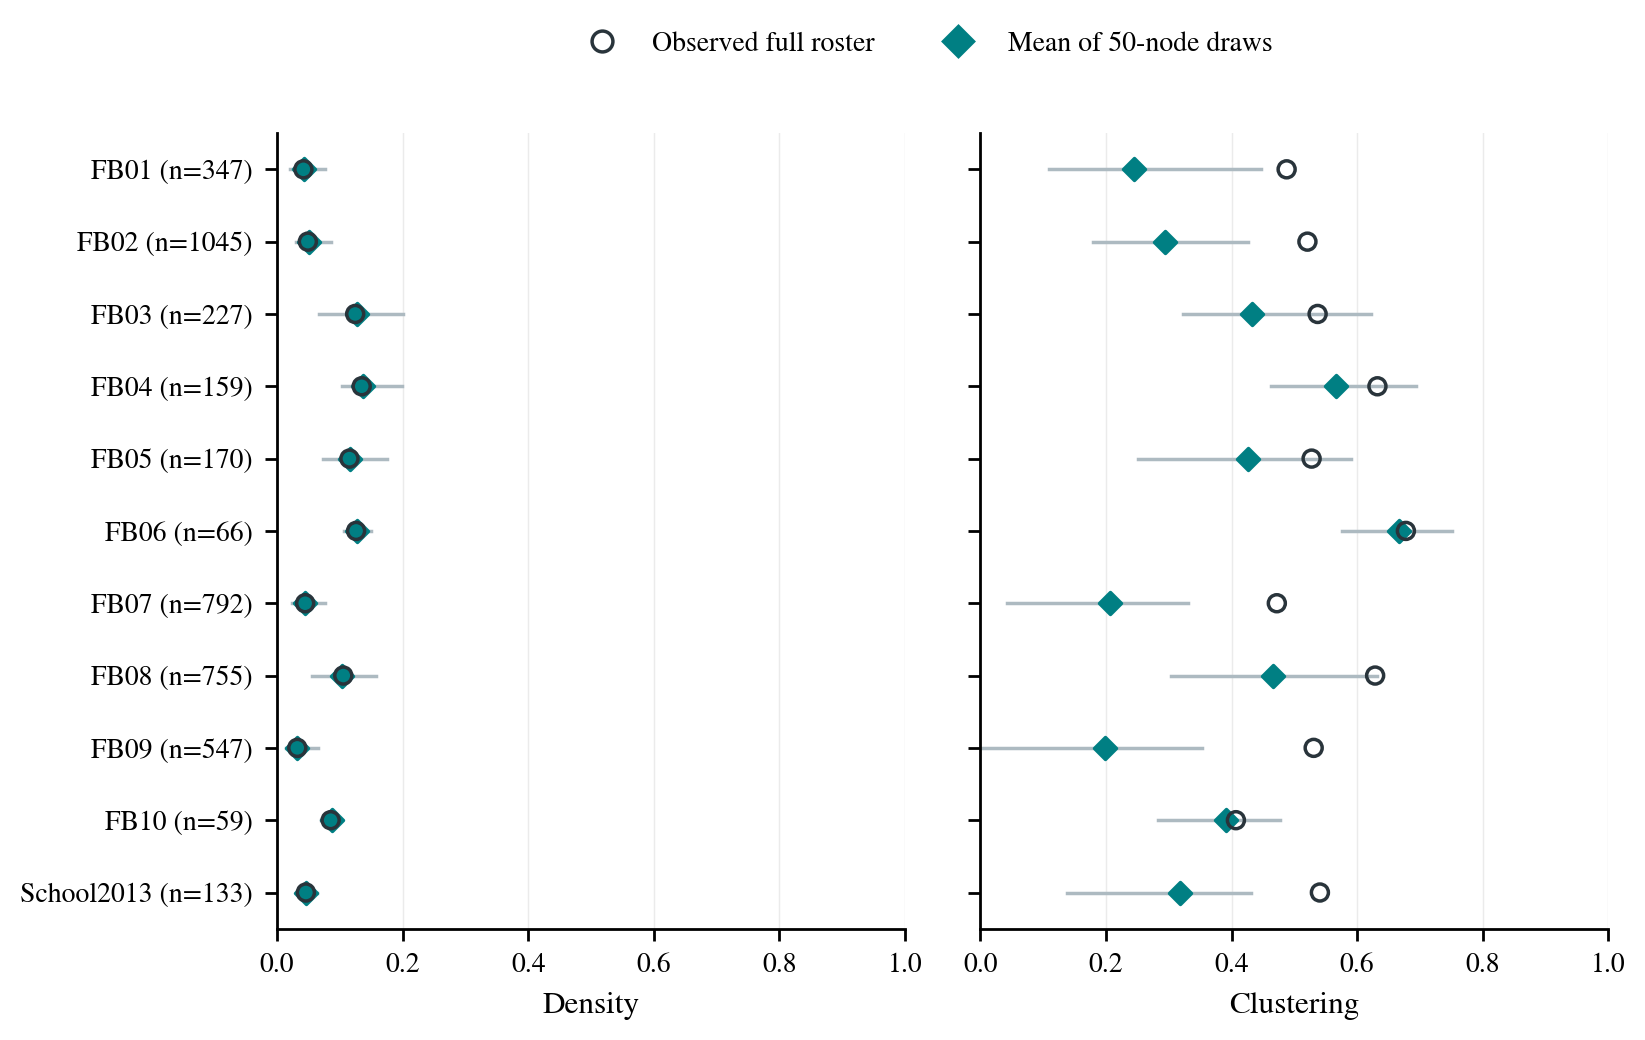

### 03 conditional structure
Mean observed-minus-control coefficients, each target equally weighted. No CIs or null p-values; finite degree swaps are a diagnostic.

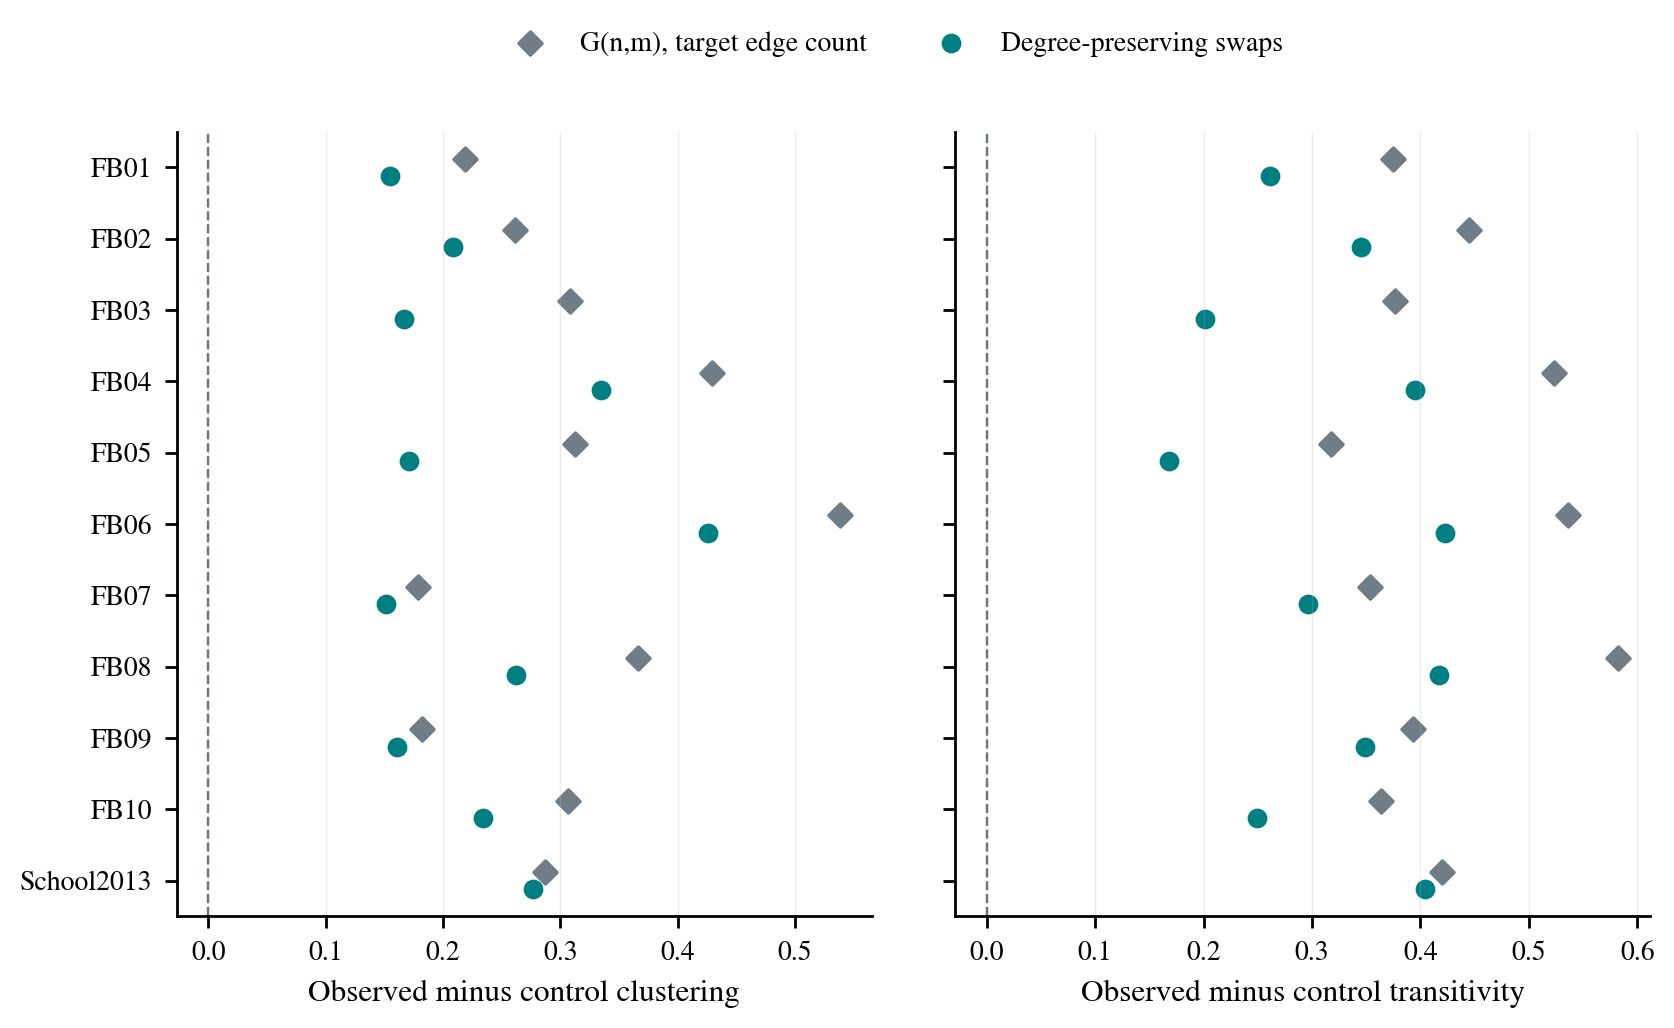

### 04 cohort sensitivity
Clustering distances by source record; adjacent Facebook records can share people and ties. They are not independent test populations.

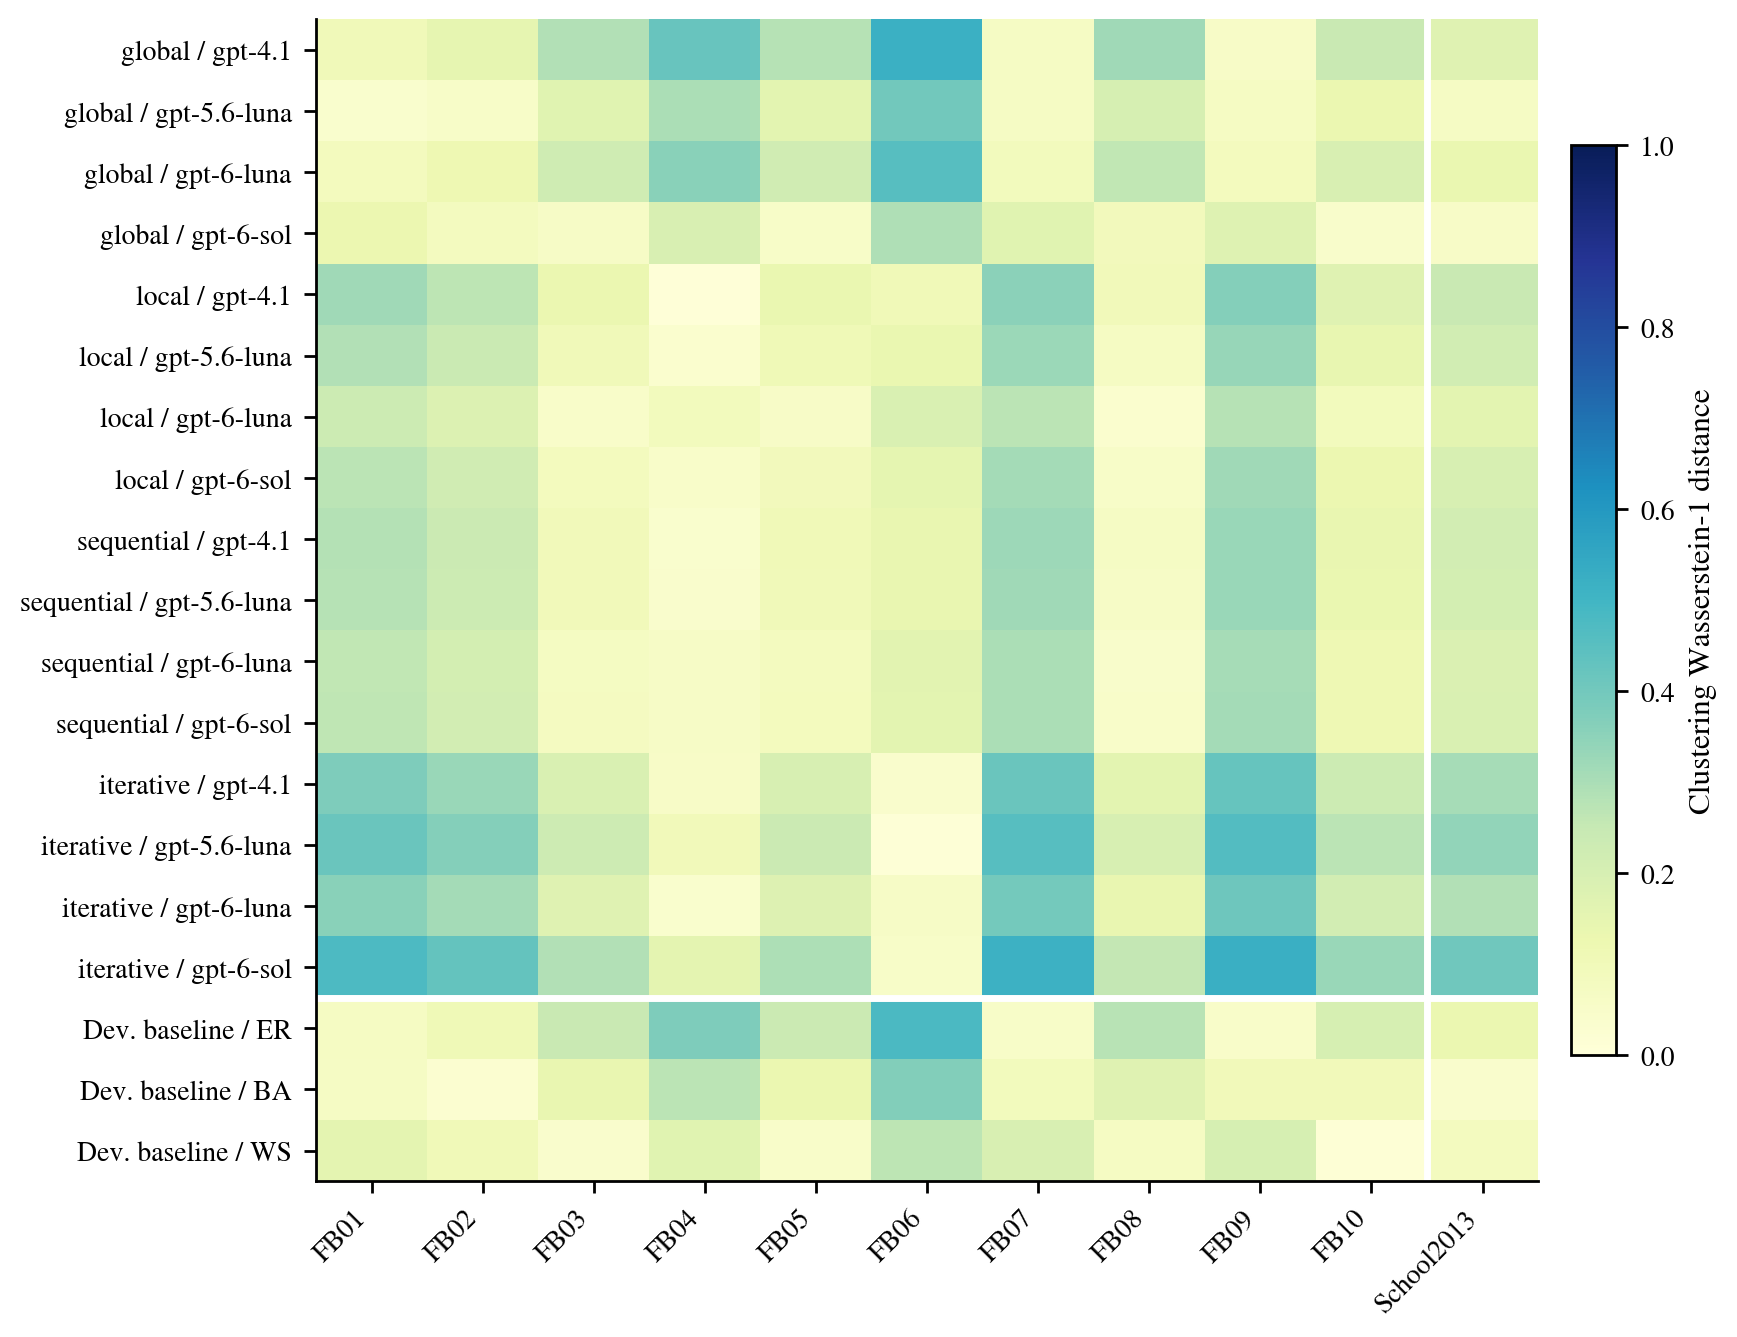

In [5]:
for stem, caption in [('01_heldout_transfer','Metric-specific transfer distances; smaller is closer on that metric, not generally better. Baseline entries average eight banks.'), ('02_sampling_shift','Open circles: complete observed roster. Diamonds: means of 32 induced 50-node draws. Lines: minimum-to-maximum node-draw range, NOT confidence intervals.'), ('03_conditional_structure','Mean observed-minus-control coefficients, each target equally weighted. No CIs or null p-values; finite degree swaps are a diagnostic.'), ('04_cohort_sensitivity','Clustering distances by source record; adjacent Facebook records can share people and ties. They are not independent test populations.')]:
    display(Markdown('### '+stem.replace('_',' ')+'\n'+caption))
    display(Image(filename=str(OUT/'figures'/(stem+'.png'))))


## Findings and limits in simple words
- No procedure is closest on every metric. Classical baselines remain competitive: WS has lower mean clustering distance than each four-model procedure average on Facebook; BA does on the school sample. This is descriptive, not a significance test.
- Global graphs better match sparse density/efficiency here, but matching a few summaries is not human behavioral validation. Dense legacy development data also make transfer harder for those classical baselines.
- Node sampling changes clustering markedly; comparing full networks of different sizes could mislead. The observed public graphs retain positive clustering residuals after degree-preserving controls, but no conclusion about national culture follows.
- The human data are legacy convenience sources, the school survey is incomplete, Facebook egonets overlap, and draws are dependent. There are two source studies, not 352 independent populations. Raw source-member filenames are retained for provenance; no profile features or person-level graph rows are published here.
- Review the separate clean manuscript figures in notebook 04. The original primary analysis and original plots remain archived unchanged.

Reproduction: use scripts/fetch_heldout_public.py to obtain hash-pinned public data, then scripts/run_heldout_evaluation.py --cache <folder>. This notebook itself uses published tables only and never downloads data or calls models.